# KHÁM PHÁ VÀ PHÂN TÍCH THỊ TRƯỜNG TUYỂN DỤNG IT (EDA)
## DỰ ÁN: IT JOB MARKET INTELLIGENCE
---
Notebook này tập trung phân tích khám phá dữ liệu (Exploratory Data Analysis - EDA) trên tập dữ liệu việc làm IT đã được làm sạch và chuẩn hóa.

Nội dung phân tích gồm:
1. Nạp và kiểm tra cấu trúc dữ liệu tổng quan
2. Độ hoàn thiện dữ liệu & Tỷ lệ thiếu theo trường (Missing Rate)
3. Cơ cấu mô hình làm việc (Work Mode) & Hình thức (Employment Type)
4. Phân tích kinh nghiệm và phân bố mức lương theo thành phố
5. Tỷ lệ tin tuyển dụng còn hiệu lực (is_active)
6. Đặc trưng mô tả công việc và Top kỹ năng công nghệ phổ biến nhất

## 1. Nạp tập dữ liệu sạch từ file CSV

In [1]:
import os
import re
import pandas as pd
import numpy as np

# 1. Tự động xác định đường dẫn gốc dự án
current_dir = os.path.dirname(os.path.abspath('__file__')) if '__file__' in locals() else os.getcwd()
project_root = current_dir
while not os.path.exists(os.path.join(project_root, 'data')) and os.path.dirname(project_root) != project_root:
    project_root = os.path.dirname(project_root)

csv_path = os.path.join(project_root, 'data', 'notebook', 'content_base', 'jobs_clean.csv')

# 2. Đọc file CSV dữ liệu việc làm sạch mới nhất
jobs = pd.read_csv(csv_path)
print(f"Đã nạp thành công dữ liệu: {jobs.shape[0]:,} dòng x {jobs.shape[1]} cột")
print(f"Nguồn dữ liệu: {csv_path}")
print("Danh sách các cột:", list(jobs.columns))
jobs.head(5)


Đã nạp thành công dữ liệu: 5,234 dòng x 20 cột
Nguồn dữ liệu: C:\Users\Minh Doan\repo_github\IT-Job-Market-Intelligence\data\notebook\content_base\jobs_clean.csv
Danh sách các cột: ['job_id', 'company_name', 'title', 'description_clean', 'required_skills', 'preferred_skills', 'job_tags', 'experience_min', 'experience_max', 'location', 'city', 'salary_min', 'salary_max', 'employment_type', 'work_mode', 'deadline', 'is_active', 'is_it', 'job_url', 'company_logo_url']


,job_id,company_name,title,description_clean,required_skills,preferred_skills,job_tags,experience_min,experience_max,location,city,salary_min,salary_max,employment_type,work_mode,deadline,is_active,is_it,job_url,company_logo_url
0,topcv_2314643,ZIGExN VeNtura,Full-Stack Web Engineer Intern/Fresher (AI Cod...,COMPANY INTRODUCTION\nAbout our parent company...,"Python, Java, JavaScript, C#, PHP, Golang, Rub...",NaN,"Fullstack Developer, IT - Phần mềm, Tiếng Anh ...",0.0,0.0,"Floor 11, Vina Building, 131 Xo Viet Nghe Tinh...",Hồ Chí Minh,NaN,NaN,Intern,Onsite,2026-10-28,False,True,https://www.topcv.vn/viec-lam/full-stack-web-e...,https://static.topcv.vn/company_logos/67c94ea3...
1,topcv_2314547,Điện tử R&P,Kỹ Sư Hệ Thống Nhúng,"R&P là công ty công nghệ, hoạt động trên lĩnh ...","C++, Linux, ERP, Embedded",NaN,"Embedded Engineer/Lập trình nhúng, Điện / Điện...",0.0,0.0,"65 Lê Trung Nghĩa, Phường Bảy Hiền, Hồ Chí Minh",Hồ Chí Minh,NaN,NaN,Full-time,Onsite,2026-10-28,False,True,https://www.topcv.vn/viec-lam/ky-su-he-thong-n...,https://static.topcv.vn/company_logos/cong-ty-...
2,topcv_2321616,FOXSCORE,UI/UX Designer - Mobile App,FOXSCORE – NỀN TẢNG THỂ THAO THÔNG MINH\nRa đờ...,"Android, iOS, Figma, UX Design",NaN,"Product Owner/Product Manager, IT - Phần mềm, ...",2.0,2.0,"62/6-8-10 Trương Công Định, Phường Tân Bình, H...",Hồ Chí Minh,15000000.0,15000000.0,Full-time,Onsite,2026-11-05,False,True,https://www.topcv.vn/viec-lam/ui-ux-designer-m...,https://static.topcv.vn/company_logos/ELdaFFf6...
3,topcv_2315450,THƯƠNG MẠI QUỐC TẾ LB GLOBAL,Business Analyst - Data Hệ Thống Phân Phối - C...,CÔNG TY CỔ PHẦN THƯƠNG MẠI QUỐC TẾ LB GLOBAL\n...,"Excel, LLM",NaN,Vận hành sàn thương mại điện tử,0.2,0.2,"Phường Cầu Giấy, Hà Nội",Hà Nội,12000000.0,12000000.0,Full-time,Onsite,2026-10-28,False,True,https://www.topcv.vn/viec-lam/business-analyst...,https://static.topcv.vn/company_logos/vyUiIf9h...
4,topcv_2315936,VODAPLAY,Junior QA Tester (Manual Testing),CÔNG TY TNHH VODAPLAY VIỆT NAM\n- Mã số thuế 0...,Manual Testing,NaN,"Manual Tester, IT - Phần mềm",1.0,1.0,"Phường Cầu Giấy, Hà Nội",Hà Nội,NaN,16000000.0,Full-time,Onsite,2026-10-29,False,True,https://www.topcv.vn/viec-lam/junior-qa-tester...,https://static.topcv.vn/company_logos/cong-ty-...


## 2. Kiểm tra Cấu trúc dữ liệu & Kiểu dữ liệu (Data Types)

In [2]:
print("=== TỔNG QUAN KIỂU DỮ LIỆU & BỘ NHỚ ===")
jobs.info()


=== TỔNG QUAN KIỂU DỮ LIỆU & BỘ NHỚ ===
<class 'pandas.DataFrame'>
RangeIndex: 5234 entries, 0 to 5233
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   job_id             5234 non-null   str    
 1   company_name       5234 non-null   str    
 2   title              5234 non-null   str    
 3   description_clean  5234 non-null   str    
 4   required_skills    3806 non-null   str    
 5   preferred_skills   32 non-null     str    
 6   job_tags           5108 non-null   str    
 7   experience_min     5234 non-null   float64
 8   experience_max     5233 non-null   float64
 9   location           5233 non-null   str    
 10  city               5234 non-null   str    
 11  salary_min         2143 non-null   float64
 12  salary_max         2416 non-null   float64
 13  employment_type    5234 non-null   str    
 14  work_mode          5234 non-null   str    
 15  deadline           5234 non-null   str    


## 3. Kiểm tra Độ đầy đủ dữ liệu (Completeness & Missing Rate)

In [3]:
total_rows = len(jobs)
missing_stats = []

for col in jobs.columns:
    null_count = jobs[col].isnull().sum()
    empty_count = (jobs[col].astype(str).str.strip() == '').sum() if jobs[col].dtype == 'object' else 0
    total_missing = null_count + empty_count
    missing_pct = (total_missing / total_rows) * 100
    valid_pct = 100.0 - missing_pct
    
    missing_stats.append({
        'Cột': col,
        'Số dòng thiếu': total_missing,
        'Tỷ lệ thiếu (%)': round(missing_pct, 2),
        'Độ đầy đủ (%)': round(valid_pct, 2)
    })

df_missing = pd.DataFrame(missing_stats).sort_values(by='Độ đầy đủ (%)', ascending=False)
display(df_missing)


,Cột,Số dòng thiếu,Tỷ lệ thiếu (%),Độ đầy đủ (%)
0,job_id,0,0.00,100.00
1,company_name,0,0.00,100.00
2,title,0,0.00,100.00
3,description_clean,0,0.00,100.00
7,experience_min,0,0.00,100.00
10,city,0,0.00,100.00
17,is_it,0,0.00,100.00
18,job_url,0,0.00,100.00
16,is_active,0,0.00,100.00
15,deadline,0,0.00,100.00


### 3.1. Biểu đồ Tỷ lệ thiếu dữ liệu theo cột (%)

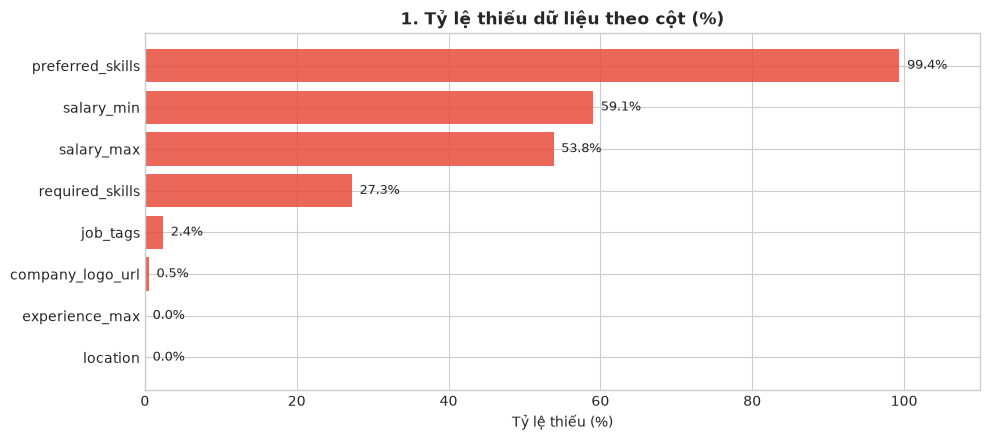

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

missing_plot_data = df_missing[df_missing['Số dòng thiếu'] > 0].sort_values(by='Tỷ lệ thiếu (%)', ascending=True)

plt.figure(figsize=(10, 4.5))
bars = plt.barh(missing_plot_data['Cột'], missing_plot_data['Tỷ lệ thiếu (%)'], color='#e74c3c', alpha=0.85)
plt.title('1. Tỷ lệ thiếu dữ liệu theo cột (%)', fontsize=12, fontweight='bold')
plt.xlabel('Tỷ lệ thiếu (%)')
for idx, val in enumerate(missing_plot_data['Tỷ lệ thiếu (%)']):
    plt.text(val + 1, idx, f"{val:.1f}%", va='center', fontsize=9)
plt.xlim(0, 110)
plt.tight_layout()
plt.show()


## 4. Phân bố các trường phân loại (Categorical Distribution)

In [5]:
# 1. Phân bố theo thành phố
print("=== 1. PHÂN BỐ THEO THÀNH PHỐ (CITY) ===")
city_df = jobs['city'].value_counts(dropna=False).reset_index()
city_df.columns = ['Thành phố', 'Số lượng']
city_df['Tỷ lệ (%)'] = (city_df['Số lượng'] / len(jobs) * 100).round(2)
display(city_df)

# 2. Phân bố theo mô hình làm việc
print("\n=== 2. PHÂN BỐ THEO MÔ HÌNH LÀM VIỆC (WORK_MODE) ===")
wm_df = jobs['work_mode'].value_counts(dropna=False).reset_index()
wm_df.columns = ['Work Mode', 'Số lượng']
wm_df['Tỷ lệ (%)'] = (wm_df['Số lượng'] / len(jobs) * 100).round(2)
display(wm_df)

# 3. Phân bố theo hình thức làm việc
print("\n=== 3. PHÂN BỐ THEO HÌNH THỨC LÀM VIỆC (EMPLOYMENT_TYPE) ===")
emp_df = jobs['employment_type'].value_counts(dropna=False).reset_index()
emp_df.columns = ['Employment Type', 'Số lượng']
emp_df['Tỷ lệ (%)'] = (emp_df['Số lượng'] / len(jobs) * 100).round(2)
display(emp_df)

# 4. Phân bố theo trạng thái hiệu lực
print("\n=== 4. TRẠNG THÁI HIỆU LỰC (IS_ACTIVE) ===")
act_df = jobs['is_active'].value_counts(dropna=False).reset_index()
act_df.columns = ['Is Active', 'Số lượng']
act_df['Tỷ lệ (%)'] = (act_df['Số lượng'] / len(jobs) * 100).round(2)
display(act_df)


=== 1. PHÂN BỐ THEO THÀNH PHỐ (CITY) ===


,Thành phố,Số lượng,Tỷ lệ (%)
0,Hà Nội,3023,57.76
1,Hồ Chí Minh,1669,31.89
2,Khác,444,8.48
3,Đà Nẵng,91,1.74
4,Toàn quốc,7,0.13



=== 2. PHÂN BỐ THEO MÔ HÌNH LÀM VIỆC (WORK_MODE) ===


,Work Mode,Số lượng,Tỷ lệ (%)
0,Onsite,5168,98.74
1,Remote,48,0.92
2,Hybrid,18,0.34



=== 3. PHÂN BỐ THEO HÌNH THỨC LÀM VIỆC (EMPLOYMENT_TYPE) ===


,Employment Type,Số lượng,Tỷ lệ (%)
0,Full-time,4953,94.63
1,Intern,251,4.80
2,Contract,19,0.36
3,Part-time,11,0.21



=== 4. TRẠNG THÁI HIỆU LỰC (IS_ACTIVE) ===


,Is Active,Số lượng,Tỷ lệ (%)
0,True,3517,67.2
1,False,1717,32.8


### 4.1. Biểu đồ Cơ cấu Mô hình làm việc (Work Mode) & Hình thức (Employment Type)

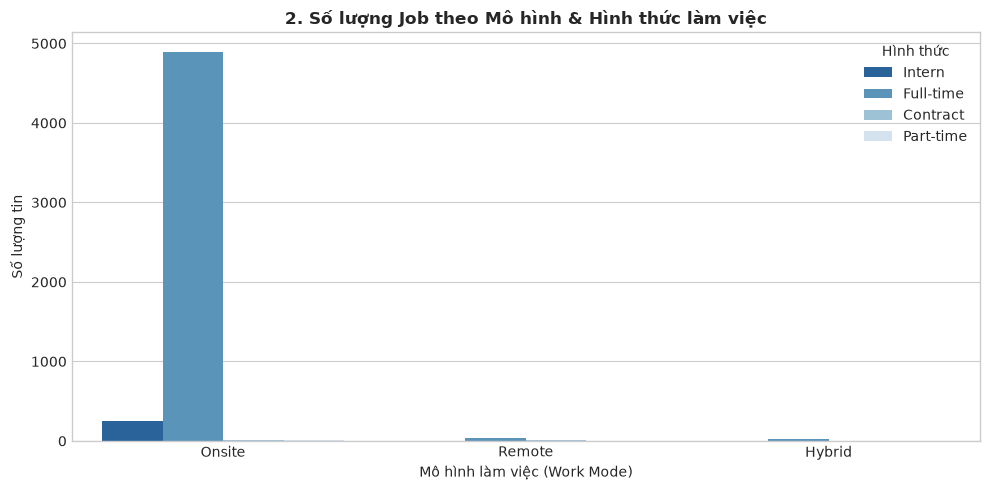

In [6]:
plt.figure(figsize=(10, 5))
sns.countplot(data=jobs, x='work_mode', hue='employment_type', palette='Blues_r')
plt.title('2. Số lượng Job theo Mô hình & Hình thức làm việc', fontsize=12, fontweight='bold')
plt.xlabel('Mô hình làm việc (Work Mode)')
plt.ylabel('Số lượng tin')
plt.legend(title='Hình thức')
plt.tight_layout()
plt.show()


### 4.2. Biểu đồ Tỷ lệ Tin tuyển dụng còn hiệu lực (is_active)

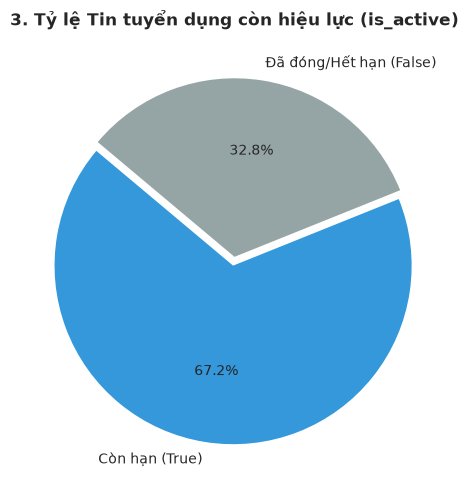

In [7]:
active_counts = jobs['is_active'].value_counts()

plt.figure(figsize=(7, 5))
plt.pie(active_counts, labels=['Còn hạn (True)', 'Đã đóng/Hết hạn (False)'], autopct='%1.1f%%',
        startangle=140, colors=['#3498db', '#95a5a6'], explode=(0.05, 0))
plt.title('3. Tỷ lệ Tin tuyển dụng còn hiệu lực (is_active)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


## 5. Thống kê mô tả các trường số (Mức lương & Kinh nghiệm)

Quy đổi cột lương sang đơn vị **triệu VNĐ/tháng** để dễ quan sát phân bố mức lương tối thiểu và tối đa.

In [8]:
# Thống kê mô tả số năm kinh nghiệm
print("=== PHÂN BỐ SỐ NĂM KINH NGHIỆM (NĂM) ===")
display(jobs[['experience_min', 'experience_max']].describe().round(2))

# Thống kê mức lương theo đơn vị triệu VNĐ/tháng
print("\n=== PHÂN BỐ MỨC LƯƠNG (TRIỆU VNĐ/THÁNG) ===")
salary_summary = pd.DataFrame({
    'Lương tối thiểu (triệu VNĐ)': (jobs['salary_min'] / 1_000_000).describe(),
    'Lương tối đa (triệu VNĐ)': (jobs['salary_max'] / 1_000_000).describe()
}).round(2)
display(salary_summary)


=== PHÂN BỐ SỐ NĂM KINH NGHIỆM (NĂM) ===


,experience_min,experience_max
count,5234.00,5233.00
mean,2.27,2.27
std,1.94,1.94
min,0.00,0.00
25%,1.00,1.00
50%,2.00,2.00
75%,3.00,3.00
max,20.00,20.00



=== PHÂN BỐ MỨC LƯƠNG (TRIỆU VNĐ/THÁNG) ===


,Lương tối thiểu (triệu VNĐ),Lương tối đa (triệu VNĐ)
count,2143.00,2416.00
mean,16.23,23.69
std,12.73,18.85
min,1.00,1.00
25%,10.00,12.00
50%,13.00,20.00
75%,20.00,30.00
max,300.00,300.00


### 5.1. Biểu đồ Phân bố Số năm kinh nghiệm tối thiểu yêu cầu

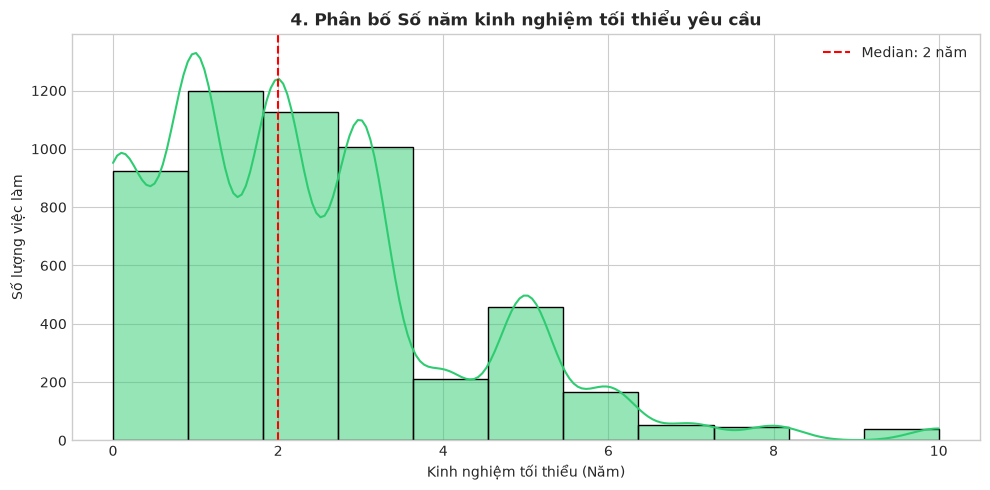

In [9]:
exp_clean = jobs['experience_min'].dropna()

plt.figure(figsize=(10, 5))
sns.histplot(exp_clean[exp_clean <= 10], bins=11, kde=True, color='#2ecc71')
plt.axvline(exp_clean.median(), color='red', linestyle='--', label=f"Median: {exp_clean.median():.0f} năm")
plt.title('4. Phân bố Số năm kinh nghiệm tối thiểu yêu cầu', fontsize=12, fontweight='bold')
plt.xlabel('Kinh nghiệm tối thiểu (Năm)')
plt.ylabel('Số lượng việc làm')
plt.legend()
plt.tight_layout()
plt.show()


### 5.2. Biểu đồ Boxplot Phân bố Mức lương tối đa theo Thành phố (Triệu VNĐ/tháng)

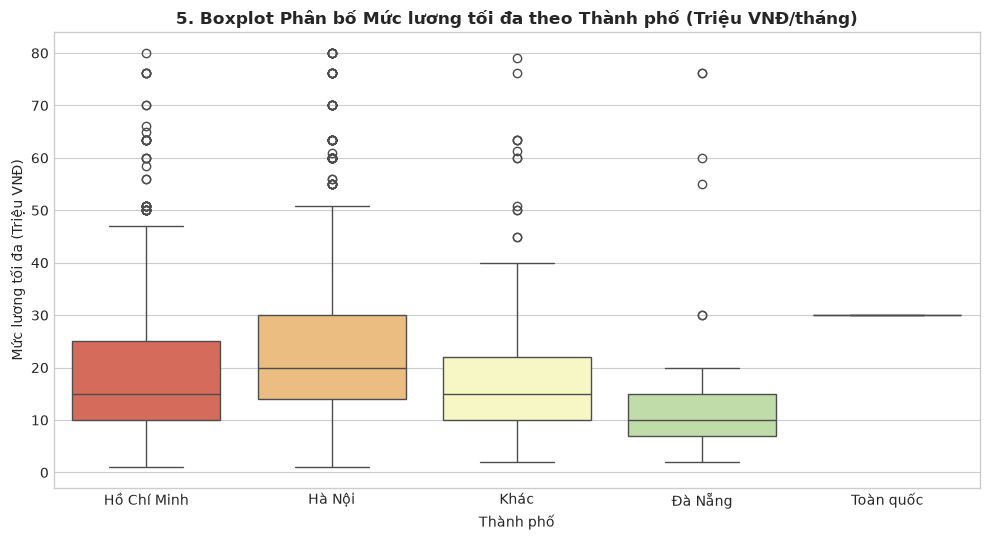

In [10]:
sal_df = jobs[jobs['salary_max'].notna() & (jobs['salary_max'] <= 80e6) & (jobs['salary_max'] > 0)].copy()
sal_df['salary_max_mil'] = sal_df['salary_max'] / 1e6

plt.figure(figsize=(10, 5.5))
sns.boxplot(data=sal_df, x='city', y='salary_max_mil', hue='city', palette='Spectral', legend=False)
plt.title('5. Boxplot Phân bố Mức lương tối đa theo Thành phố (Triệu VNĐ/tháng)', fontsize=12, fontweight='bold')
plt.xlabel('Thành phố')
plt.ylabel('Mức lương tối đa (Triệu VNĐ)')
plt.tight_layout()
plt.show()


## 6. Phân tích đặc trưng văn bản & Top Kỹ năng yêu cầu

In [11]:
# 1. Thống kê độ dài văn bản mô tả công việc (description_clean)
desc_lengths = jobs['description_clean'].dropna().str.len()
print("=== ĐỘ DÀI MÔ TẢ CÔNG VIỆC (SỐ KÝ TỰ) ===")
display(desc_lengths.describe().round(0))

# 2. Bóc tách và đếm tần suất Top 20 kỹ năng yêu cầu
from collections import Counter

skill_counter = Counter()
for text in jobs['required_skills'].dropna():
    skills = [s.strip() for s in str(text).split(',') if s.strip()]
    skill_counter.update(skills)

top_skills_df = pd.DataFrame(skill_counter.most_common(20), columns=['Kỹ năng', 'Số lần xuất hiện'])
top_skills_df['Tỷ lệ (%)'] = (top_skills_df['Số lần xuất hiện'] / len(jobs) * 100).round(2)

print("\n=== TOP 20 KỸ NĂNG XUẤT HIỆN NHIỀU NHẤT TRONG DATASET ===")
display(top_skills_df)


=== ĐỘ DÀI MÔ TẢ CÔNG VIỆC (SỐ KÝ TỰ) ===


count     5234.0
mean      2326.0
std       1149.0
min        160.0
25%       1549.0
50%       2103.0
75%       2807.0
max      12642.0
Name: description_clean, dtype: float64


=== TOP 20 KỸ NĂNG XUẤT HIỆN NHIỀU NHẤT TRONG DATASET ===


,Kỹ năng,Số lần xuất hiện,Tỷ lệ (%)
0,SQL,719,13.74
1,Python,583,11.14
2,Photoshop,580,11.08
3,An Ninh Mạng,507,9.69
4,Agile,485,9.27
5,Data Analysis,443,8.46
6,Git,402,7.68
7,CI/CD,371,7.09
8,Linux,364,6.95
9,ERP,363,6.94


### 6.1. Biểu đồ Top 15 Kỹ năng công nghệ yêu cầu phổ biến nhất thị trường

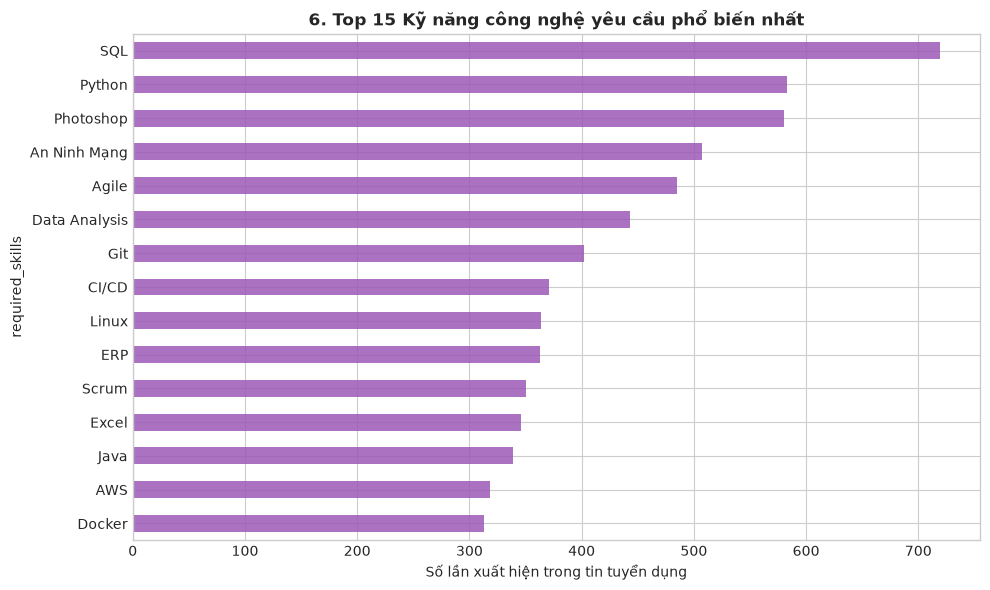

In [12]:
all_skills_series = jobs['required_skills'].dropna().str.split(',').explode().str.strip()
top15_skills = all_skills_series[all_skills_series != ''].value_counts().head(15)

plt.figure(figsize=(10, 6))
top15_skills.sort_values(ascending=True).plot(kind='barh', color='#9b59b6', alpha=0.85)
plt.title('6. Top 15 Kỹ năng công nghệ yêu cầu phổ biến nhất', fontsize=12, fontweight='bold')
plt.xlabel('Số lần xuất hiện trong tin tuyển dụng')
plt.tight_layout()
plt.show()
